# Динамика финального захода: первый аудит данных

Методика этого ноутбука – описательный аудит локальных траекторий, **без
обучения**. Будущая задача – бинарная классификация последующего GoA по
динамике до момента прогноза, с парой без погоды / с погодой.
Сначала проверяем, какие наблюдения действительно доступны. Существующие
пилоты создавались для геометрии C40 и интерполяции, поэтому их нельзя
автоматически считать выборкой финальных заходов с надежными метками.


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();BASE=ROOT/'research/final-approach-dynamics';OLD=ROOT/'research/c40_geometry/data'
files=sorted(OLD.rglob('*state_vectors*.csv'))
assert files
rows=[];columns=[]
for path in files:
    f=pd.read_csv(path,dtype={'icao24':str})
    assert {'time','icao24','lat','lon'}.issubset(f.columns)
    utc=pd.to_datetime(f.time,unit='s',utc=True)
    ordered=f.sort_values(['icao24','time'])
    gaps=ordered.groupby('icao24').time.diff();positive=gaps[gaps>0]
    age=f.time-f.lastposupdate if 'lastposupdate' in f else pd.Series(dtype=float)
    with path.open('rb') as stream:digest=hashlib.file_digest(stream,'sha256').hexdigest()
    rows.append({'source':path.relative_to(ROOT).as_posix(),'sha256':digest,'bytes':path.stat().st_size,'rows':len(f),'aircraft':f.icao24.nunique(),'utc_min':str(utc.min()),'utc_max':str(utc.max()),'median_positive_spacing_s':positive.median(),'p95_positive_spacing_s':positive.quantile(.95),'p95_position_age_s':age.quantile(.95),'negative_position_age_rows':int((age<0).sum()),'duplicate_aircraft_time_rows':int(f.duplicated(['icao24','time']).sum()),'has_GoA_label':'GoA' in f})
    for field in f:
        columns.append({'source':path.relative_to(ROOT).as_posix(),'field':field,'nonmissing_rows':int(f[field].notna().sum()),'nonmissing_fraction':f[field].notna().mean()})
inventory=pd.DataFrame(rows);fields=pd.DataFrame(columns)
inventory.to_csv(BASE/'reports/00_local_sources.csv',index=False);fields.to_csv(BASE/'reports/00_field_coverage.csv',index=False)
display(inventory)
display(fields.groupby('field').agg(files=('source','nunique'),mean_nonmissing_fraction=('nonmissing_fraction','mean')))


,source,sha256,bytes,rows,aircraft,utc_min,utc_max,median_positive_spacing_s,p95_positive_spacing_s,p95_position_age_s,negative_position_age_rows,duplicate_aircraft_time_rows,has_GoA_label
0,research/c40_geometry/data/expanded_training/2...,1bb1dd25017ac7a389e260d777a5153d1fdcb309a8d343...,339348,1811,7,2019-11-04 22:00:00+00:00,2019-11-04 22:59:30+00:00,10.0,10.0,183.57200,0,0,False
1,research/c40_geometry/data/expanded_training/2...,3899c788b9eee00fb452b2656935853463f985b5fb994d...,331406,1790,6,2019-11-11 22:00:10+00:00,2019-11-11 22:59:50+00:00,10.0,10.0,132.02395,0,0,False
2,research/c40_geometry/data/expanded_training/2...,6f0cdedc31d536a26f36f173c3ae79bafbcb082e7dea7a...,561362,3040,12,2019-11-18 22:00:00+00:00,2019-11-18 22:59:50+00:00,10.0,10.0,174.92410,0,0,False
3,research/c40_geometry/data/expanded_training/2...,9ee84f38d381ef06bf10b93bc3f77dd5968b8f5d5a4de6...,353968,1903,8,2019-11-25 22:00:10+00:00,2019-11-25 22:59:50+00:00,10.0,10.0,176.98410,0,0,False
4,research/c40_geometry/data/expanded_training/2...,2d54e2552c44a1223e932b8d075cb03f2e80efca579014...,453220,2474,9,2019-12-02 22:00:10+00:00,2019-12-02 22:59:50+00:00,10.0,10.0,157.09210,0,0,False
5,research/c40_geometry/data/external_day/state_...,cf0a0bd329959b5d1fa5b4decca4d0d9a11a7d28d2e47f...,413207,2236,10,2019-10-28 22:00:10+00:00,2019-10-28 22:47:40+00:00,10.0,10.0,200.12510,0,0,False
6,research/c40_geometry/data/hermite_validation/...,dcab3c81c164456b78892c6c67a6c0e6d32c74ce131781...,324950,1761,7,2019-12-09 22:00:00+00:00,2019-12-09 22:59:50+00:00,10.0,10.0,183.99800,0,0,False
7,research/c40_geometry/data/hermite_validation/...,c63d71dffb8d2f319fb8b7abb1bfb138bfef93b37c0d2d...,410718,2240,8,2019-12-16 22:00:10+00:00,2019-12-16 22:59:50+00:00,10.0,10.0,167.68225,0,0,False
8,research/c40_geometry/data/public_pilot/ENT73J...,7d3e266f40e4448ec0602b568efb1e9f9cda2420fc2666...,65233,359,1,2019-10-21 22:00:10+00:00,2019-10-21 22:59:50+00:00,10.0,10.0,0.39000,0,0,False
9,research/c40_geometry/data/public_pilot/ENT73J...,027285248d141317b3de68bc908606f74ba0ceac216c53...,21769,130,1,2019-10-21 23:00:10+00:00,2019-10-21 23:21:40+00:00,10.0,10.0,234.99000,0,0,False


,files,mean_nonmissing_fraction
field,,
alert,11,1.000000
baroaltitude,11,0.890643
callsign,11,1.000000
geoaltitude,11,0.854640
heading,11,0.997387
icao24,11,1.000000
lastcontact,11,1.000000
lastposupdate,11,0.999904
lat,11,0.999904


## Интервалы наблюдений и свежесть позиций

Время строки и время обновления позиции различаются. Медиана и 95-й
процентиль интервала вычисляются внутри ICAO24 по положительным разностям.
Дубли отдельно отмечены, отрицательный возраст позиции не исправляется.
Число строк разных файлов не является числом независимых событий: источники
могут перекрываться. Оценки относятся только к этим локальным пилотам.


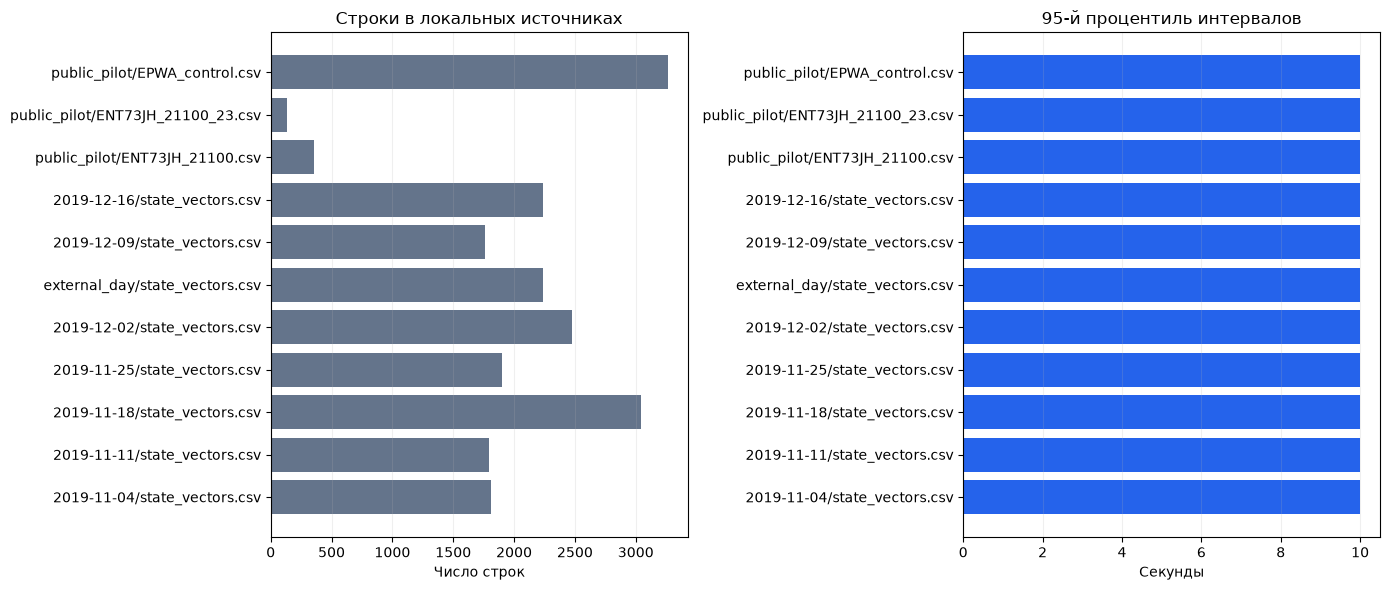

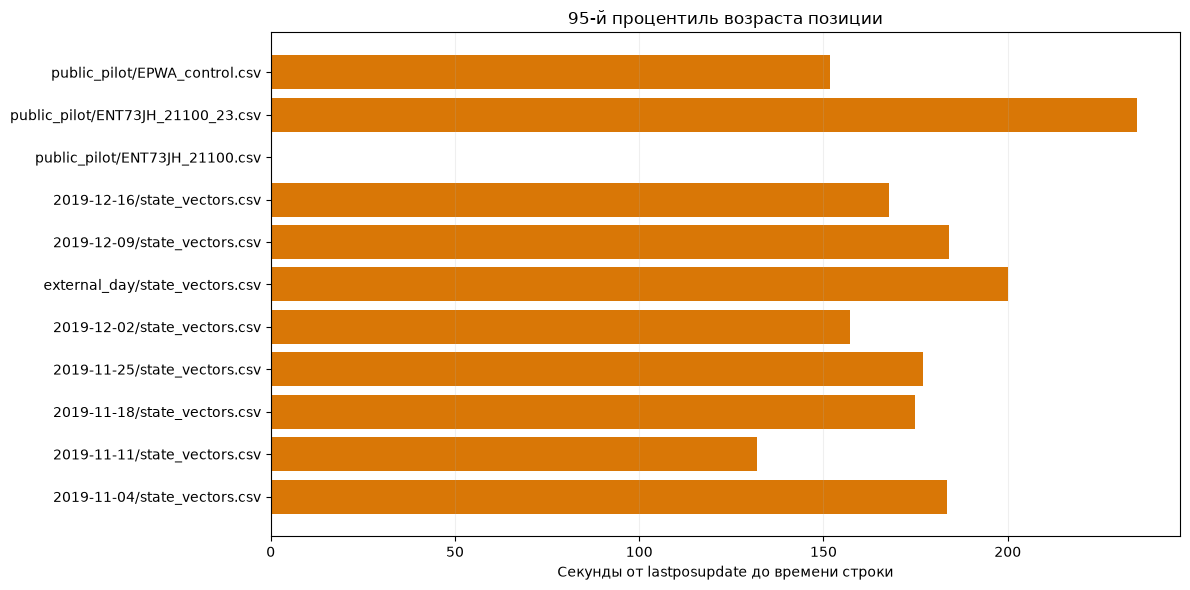

In [2]:
labels=[Path(x).parent.name+'/'+Path(x).name.replace('_state_vectors','') for x in inventory.source]
fig,axes=plt.subplots(1,2,figsize=(14,6))
axes[0].barh(labels,inventory.rows,color='#64748b');axes[0].set(title='Строки в локальных источниках',xlabel='Число строк')
axes[1].barh(labels,inventory.p95_positive_spacing_s,color='#2563eb');axes[1].set(title='95-й процентиль интервалов',xlabel='Секунды')
for ax in axes:ax.grid(axis='x',alpha=.2)
fig.tight_layout()
for ext in ['png','svg']:fig.savefig(BASE/f'figures/00_source_inventory.{ext}',dpi=160,bbox_inches='tight')
plt.show()
fig,ax=plt.subplots(figsize=(12,6))
ax.barh(labels,inventory.p95_position_age_s,color='#d97706')
ax.set(title='95-й процентиль возраста позиции',xlabel='Секунды от lastposupdate до времени строки')
ax.grid(axis='x',alpha=.2);fig.tight_layout()
for ext in ['png','svg']:fig.savefig(BASE/f'figures/02_position_freshness.{ext}',dpi=160,bbox_inches='tight')
plt.show()


## Пример последовательности движения

Показываем наблюдения одного самолета из локального пилота. Горизонтальная
ось – время относительно первого показанного наблюдения, без выравнивания
по будущему касанию или уходу. Окно не считается установленным финальным
участком или моментом захвата ILS. Поля показаны в исходных единицах файла;
их происхождение и преобразования должны быть проверены до расчета признаков.
Не отождествляем velocity с IAS, heading с курсом носа и baroaltitude с AGL.


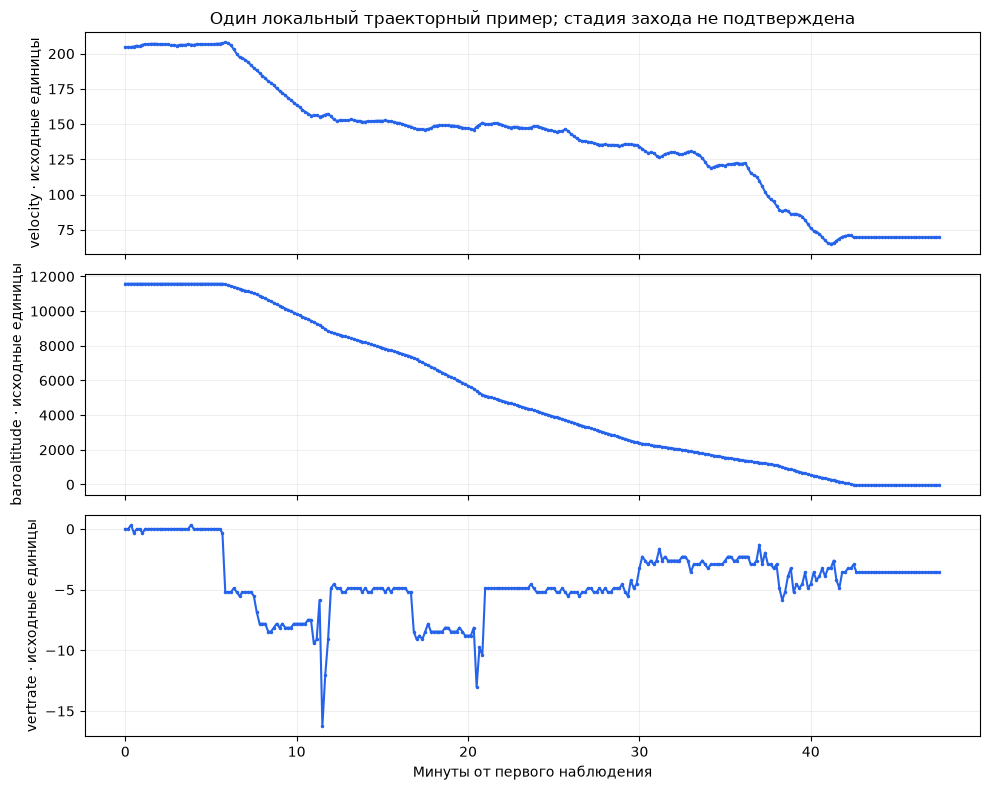

,rows,duration_minutes,GoA_label_present,ILS_capture_observed,final_segment_verified
0,286,47.5,False,False,False


In [3]:
path=OLD/'external_day/state_vectors.csv';raw=pd.read_csv(path,dtype={'icao24':str})
aircraft=raw.groupby('icao24').size().idxmax()
example=raw[raw.icao24==aircraft].sort_values('time').drop_duplicates('time')
minutes=(example.time-example.time.min())/60
fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
for ax,field in zip(axes,['velocity','baroaltitude','vertrate']):
    ax.plot(minutes,example[field],'.-',color='#2563eb',markersize=3)
    ax.set_ylabel(field+' · исходные единицы');ax.grid(alpha=.2)
axes[0].set_title('Один локальный траекторный пример; стадия захода не подтверждена')
axes[-1].set_xlabel('Минуты от первого наблюдения');fig.tight_layout()
for ext in ['png','svg']:fig.savefig(BASE/f'figures/01_local_sequence.{ext}',dpi=160,bbox_inches='tight')
plt.show()
display(pd.DataFrame([{'rows':len(example),'duration_minutes':float(minutes.max()),'GoA_label_present':'GoA' in example,'ILS_capture_observed':False,'final_segment_verified':False}]))


## Готовность к новому исследованию

Наличие рядов подтверждает возможность анализа динамики, но не готовность
выборки. Пилоты предыдущего исследования не заменяют проверку покрытий и
связи с исходами. До обучения нужны обе группы, единицы и момент прогноза.


In [4]:
readiness=pd.DataFrame([
 {'requirement':'Локальные временные последовательности','status':'есть','next':'Проверить покрытие финальных участков'},
 {'requirement':'Прямая метка GoA в файлах state vectors','status':'есть' if inventory.has_GoA_label.any() else 'нет','next':'Связать с исходной разметкой и проверить попытки'},
 {'requirement':'Наблюдаемый захват ILS','status':'не подтвержден','next':'Отделить факт захвата от геометрического приближения'},
 {'requirement':'Единицы и история преобразований','status':'нужна проверка','next':'Проверить источник каждого поля'},
 {'requirement':'Момент, окно и горизонт прогноза','status':'не заданы','next':'Зафиксировать правило из доступных к моменту данных'},
 {'requirement':'Достаточное покрытие GoA и обычных посадок','status':'не проверено','next':'Построить аудит связанных финальных участков'},
 {'requirement':'Погода до нового момента прогноза','status':'новый join не построен','next':'Повторно привязать METAR к этому моменту, не брать C40 join'},
 {'requirement':'Разделение train/validation/test','status':'не задано','next':'Разделить по времени с группировкой попыток одного полета'}])
readiness.to_csv(BASE/'reports/00_readiness.csv',index=False);display(readiness)
manifest={'method':'descriptive local trajectory inventory; no fitting','source_files':len(inventory),'source_files_with_GoA':int(inventory.has_GoA_label.sum()),'training_started':False,'final_segment_verified':False,'weather_join_built':False,'sources':inventory[['source','sha256']].to_dict('records')}
(BASE/'reports/00_inventory_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n',encoding='utf8')
for path in (BASE/'figures').glob('*.svg'):path.write_text('\n'.join(x.rstrip() for x in path.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')


,requirement,status,next
0,Локальные временные последовательности,есть,Проверить покрытие финальных участков
1,Прямая метка GoA в файлах state vectors,нет,Связать с исходной разметкой и проверить попытки
2,Наблюдаемый захват ILS,не подтвержден,Отделить факт захвата от геометрического прибл...
3,Единицы и история преобразований,нужна проверка,Проверить источник каждого поля
4,"Момент, окно и горизонт прогноза",не заданы,Зафиксировать правило из доступных к моменту д...
5,Достаточное покрытие GoA и обычных посадок,не проверено,Построить аудит связанных финальных участков
6,Погода до нового момента прогноза,новый join не построен,"Повторно привязать METAR к этому моменту, не б..."
7,Разделение train/validation/test,не задано,Разделить по времени с группировкой попыток од...
